# HMS — is the long-context gain a recording-boundary shortcut? (confirmation)

**GPU (T4), ~20–25 min.** Inputs: (1) HMS competition data; (2) the output of the notebook version that **ran v3** — it holds the `*_s1.pt` checkpoints and all `*_valpred.npy` files. (The GRU @200 s checkpoints live in the v4 version's output; if only the v3 output is attached, GRU is skipped in part 1 and everything else runs.)

**Background.** 55 % of HMS EEGs are recordings barely longer than the labelled 50 s, yet 200 s models beat 50 s models by 9–16 % on exactly those EEGs — where they see the same signal plus zero padding. Hypothesis: the padding mask tells the model how long the recording is, and recording length differs systematically between annotation rounds (and hence label mixes).

**Tests**
1. **Intervention**: re-score every EEG with the trained 200 s models while hiding the recording boundary (mirror-padding, mask = "real"), and while making every EEG look short (keep only the central 50 s).
2. **Information test**: how much a model that sees only the boundary (seconds of real signal left/right of the label) predicts, and whether adding the boundary to the 50 s model reproduces the 200 s model's gain.
3. **Clean benchmark**: calibrated Mamba vs Transformer / GRU / CNN at 50 s, where no padding exists (bootstrap CIs, Holm-corrected).

## 0. Fetch the v3 checkpoints (Version 4 of the training notebook) through the Kaggle API
Needs **Internet on** and a Kaggle Secret named `KAGGLE_API_TOKEN` (Add-ons → Secrets) holding your API token. Skipped automatically if the checkpoints are already available.

In [1]:
import os, glob, subprocess, sys
V3_REF = "beakedjungle90/notebook86c832275b/4"        # owner/notebook/version that ran v3
V3_DST = "/kaggle/working/v3ckpt"
NEEDED = [f"{m}_ctx200_f{f}_s1.pt" for m in ("mamba", "transformer", "cnn", "mamba_causal") for f in range(5)]
have = {os.path.basename(p) for p in glob.glob("/kaggle/input/**/*_s1.pt", recursive=True) + glob.glob(f"{V3_DST}/**/*_s1.pt", recursive=True)}
if all(n in have for n in NEEDED):
    print("v3 checkpoints already available, skipping download")
else:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["KAGGLE_API_TOKEN"] = UserSecretsClient().get_secret("KAGGLE_API_TOKEN")
    except Exception as e:
        print("could not read the KAGGLE_API_TOKEN secret:", e)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=False)   # the new token format needs a recent CLI
    os.makedirs(V3_DST, exist_ok=True)
    try:
        r = subprocess.run(["kaggle", "kernels", "output", V3_REF, "-p", V3_DST, "--file-pattern", r".*_s1\.pt"], capture_output=True, text=True)
        if r.returncode != 0:
            print("retrying without --file-pattern:", (r.stderr or r.stdout)[-400:])
            r = subprocess.run(["kaggle", "kernels", "output", V3_REF, "-p", V3_DST], capture_output=True, text=True)
        print(r.stdout[-600:], r.stderr[-600:])
    except FileNotFoundError:
        print("kaggle CLI not found and could not be installed: is Internet switched on in the session options?")
    got = {os.path.basename(p) for p in glob.glob(f"{V3_DST}/**/*_s1.pt", recursive=True)}
    missing = [n for n in NEEDED if n not in got and n not in have]
    print(f"{len(got)} stage-1 checkpoints downloaded; missing for this analysis: {missing if missing else 'none'}")

sults_v3/transformer_ctx50_f1_s1.pt

Output file downloaded to /kaggle/working/v3ckpt/results_v3/transformer_ctx50_f2_s1.pt

Output file downloaded to /kaggle/working/v3ckpt/results_v3/transformer_ctx50_f3_s1.pt

Output file downloaded to /kaggle/working/v3ckpt/results_v3/transformer_ctx50_f4_s1.pt
Kernel log downloaded to /kaggle/working/v3ckpt/notebook86c832275b.log 
 █▎ | 4.00M/4.80M [00:00<00:00, 11.4MB/s]
100%|██████████| 4.80M/4.80M [00:00<00:00, 11.7MB/s]

  0%|          | 0.00/4.80M [00:00<?, ?B/s]
 21%|██        | 1.00M/4.80M [00:00<00:00, 5.50MB/s]
 83%|████████▎ | 4.00M/4.80M [00:00<00:00, 14.1MB/s]
100%|██████████| 4.80M/4.80M [00:00<00:00, 15.1MB/s]

  0%|          | 0.00/4.80M [00:00<?, ?B/s]
 21%|██        | 1.00M/4.80M [00:00<00:00, 4.84MB/s]
 63%|██████▎   | 3.00M/4.80M [00:00<00:00, 11.1MB/s]
100%|██████████| 4.80M/4.80M [00:00<00:00, 13.4MB/s]

  0%|          | 0.00/4.80M [00:00<?, ?B/s]
100%|██████████| 4.80M/4.80M [00:00<00:00, 54.0MB/s]

50 stage-1 checkpoints dow

In [2]:
import os, glob, json, math, time, random, shutil
import numpy as np
import pandas as pd

CFG = dict(
    DATA_ROOT=None,                       # None = auto-detect under /kaggle/input
    CACHE_DIR="/kaggle/working/cache",    # replaced in the v2 settings cell below
    RESULTS_DIR="/kaggle/working/results",
    FS=100,                               # target sampling rate (Hz)
    CTX_SEC=50,
    CACHE_CTX_SEC=100,
    JITTER_SEC=1.0,                       # train-time random shift of the window centre
    PATCH=25,                             # samples per token (0.25 s at 100 Hz)
    N_FOLDS=5, FOLDS=[0], SEED=42,
    MODELS=["mamba", "transformer", "gru", "cnn"],
    D_MODEL=128, N_LAYERS=4, D_STATE=64, HEADDIM=32, EXPAND=2, CHUNK=64, N_HEADS_ATTN=4,
    EPOCHS=15, BATCH=64, LR=1e-3, WD=0.05, WARMUP_FRAC=0.05, CLIP=1.0,
    TRAIN_MIN_VOTES=0,
    HIGH_VOTE=10,                         # threshold for the high-agreement evaluation subset
    NUM_WORKERS=4, AMP=True,
    USE_OFFICIAL_MAMBA2=False,
    RUN_BENCHMARK=True,
    BENCH_CTX=[50, 100, 200, 400, 600, 1200],
)

In [3]:
import pyarrow.parquet as pq
import multiprocessing as mp
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, f1_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
MP = mp.get_context("fork")   # Kaggle is Linux; fork shares globals with workers
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")

def find_root():
    if CFG["DATA_ROOT"]:
        return CFG["DATA_ROOT"]
    for pat in ["/kaggle/input/*/train.csv", "/kaggle/input/*/*/train.csv"]:
        for h in glob.glob(pat):
            if os.path.isdir(os.path.join(os.path.dirname(h), "train_eegs")):
                return os.path.dirname(h)
    raise FileNotFoundError("Attach the competition data: Add Input → Competitions → HMS - Harmful Brain Activity Classification")

ROOT = find_root()
print("data:", ROOT)

device: cuda Tesla T4
data: /kaggle/input/competitions/hms-harmful-brain-activity-classification


## Labels and patient-level folds

In [4]:
VOTES = ["seizure_vote", "lpd_vote", "gpd_vote", "lrda_vote", "grda_vote", "other_vote"]
CLASSES = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]

df = pd.read_csv(f"{ROOT}/train.csv")
df["n_votes"] = df[VOTES].sum(axis=1)
P_COLS = [f"p_{c}" for c in CLASSES]
df[P_COLS] = df[VOTES].div(df["n_votes"], axis=0).to_numpy()
df["y"] = df[P_COLS].to_numpy().argmax(1)
df["center"] = df["eeg_label_offset_seconds"] + 25.0   # experts labelled the central 10 s of each 50 s window

sgkf = StratifiedGroupKFold(n_splits=CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"])
df["fold"] = -1
for k, (_, va) in enumerate(sgkf.split(df, df["y"], groups=df["patient_id"])):
    df.loc[df.index[va], "fold"] = k
assert df.groupby("patient_id")["fold"].nunique().max() == 1, "patient leaked across folds"

print(f"rows={len(df):,}  eegs={df.eeg_id.nunique():,}  patients={df.patient_id.nunique():,}")
print(df.groupby("fold").agg(rows=("eeg_id", "size"), eegs=("eeg_id", "nunique"), patients=("patient_id", "nunique")))
print(df.drop_duplicates("eeg_id")["expert_consensus"].value_counts())

rows=106,800  eegs=17,089  patients=1,950
       rows  eegs  patients
fold                       
0     17085  2795       383
1     25502  3689       386
2     21174  3585       394
3     22141  3238       397
4     20898  3782       390
expert_consensus
Other      7196
Seizure    2785
LPD        2577
GRDA       1828
GPD        1787
LRDA        916
Name: count, dtype: int64


## Preprocessing
18-channel bipolar double banana + midline (identical to I-CARE's 18 bipolar pairs). Band-pass 0.5–40 Hz at 200 Hz, then every second sample (100 Hz; the 40 Hz low-pass prevents aliasing). Amplitudes stay in µV (no per-window z-scoring), because absolute voltage — suppression, high-amplitude discharges — is clinically informative.

In [5]:
BIPOLAR = [("Fp1", "F7"), ("F7", "T3"), ("T3", "T5"), ("T5", "O1"),    # left temporal chain
           ("Fp2", "F8"), ("F8", "T4"), ("T4", "T6"), ("T6", "O2"),    # right temporal chain
           ("Fp1", "F3"), ("F3", "C3"), ("C3", "P3"), ("P3", "O1"),    # left parasagittal chain
           ("Fp2", "F4"), ("F4", "C4"), ("C4", "P4"), ("P4", "O2"),    # right parasagittal chain
           ("Fz", "Cz"), ("Cz", "Pz")]                                 # midline
FLIP_PERM = [4, 5, 6, 7, 0, 1, 2, 3, 12, 13, 14, 15, 8, 9, 10, 11, 16, 17]   # left <-> right hemisphere
ELECTRODES = sorted({e for pair in BIPOLAR for e in pair})
N_CH = len(BIPOLAR)
SRC_FS = 200
SOS = butter(4, [0.5, 40.0], btype="band", fs=SRC_FS, output="sos")
CLIP_UV = 500.0

def load_bipolar(path):
    d = pd.read_parquet(path, columns=ELECTRODES)
    d = d.interpolate(limit_direction="both").fillna(0.0)
    a = d.to_numpy(np.float32)
    col = {c: i for i, c in enumerate(ELECTRODES)}
    x = np.stack([a[:, col[p]] - a[:, col[q]] for p, q in BIPOLAR], axis=1)
    x = sosfiltfilt(SOS, x, axis=0)
    return np.clip(x, -CLIP_UV, CLIP_UV).astype(np.float32)

def _nrows(eid):
    return pq.ParquetFile(f"{ROOT}/train_eegs/{eid}.parquet").metadata.num_rows

def plan_cache(df, half_sec):
    g = df.groupby("eeg_id")["center"].agg(["min", "max"]).reset_index()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        n = pool.map(_nrows, g["eeg_id"].tolist(), chunksize=64)
    g["n_src"] = n
    s0 = np.floor((g["min"] - half_sec) * SRC_FS).clip(lower=0).astype(np.int64)
    s0 -= s0 % 2
    s1 = np.minimum(g["n_src"], np.ceil((g["max"] + half_sec) * SRC_FS)).astype(np.int64)
    g["s0"], g["length"] = s0, ((s1 - s0 + 1) // 2).clip(lower=0)
    g["offset"] = np.concatenate([[0], np.cumsum(g["length"].to_numpy())[:-1]])
    return g[["eeg_id", "n_src", "s0", "length", "offset"]]

def _build_one(args):
    eid, s0, length = args
    x = load_bipolar(f"{ROOT}/train_eegs/{eid}.parquet")[s0::2][:length]
    out = np.zeros((length, N_CH), np.float16)
    out[:len(x)] = x
    return out

def build_cache(df):
    meta_path = f"{CFG['CACHE_DIR']}/meta.json"
    want = dict(cache_ctx=CFG["CACHE_CTX_SEC"], jitter=CFG["JITTER_SEC"], fs=CFG["FS"], n_eegs=int(df.eeg_id.nunique()))
    if os.path.exists(meta_path) and json.load(open(meta_path)) == want:
        print("cache found, reusing")
        return pd.read_csv(f"{CFG['CACHE_DIR']}/index.csv")
    half = CFG["CACHE_CTX_SEC"] / 2 + CFG["JITTER_SEC"]
    idx = plan_cache(df, half)
    total = int(idx["length"].sum())
    need = total * N_CH * 2
    free = shutil.disk_usage(CFG["CACHE_DIR"]).free
    print(f"cache: {total/CFG['FS']/3600:,.1f} h of EEG, {need/1e9:.2f} GB needed, {free/1e9:.1f} GB free")
    if need > 0.9 * free:
        raise RuntimeError("Not enough disk: lower CACHE_CTX_SEC or point CACHE_DIR at a larger disk")
    mm = np.lib.format.open_memmap(f"{CFG['CACHE_DIR']}/signals.npy", mode="w+", dtype=np.float16, shape=(total, N_CH))
    jobs = list(zip(idx["eeg_id"], idx["s0"], idx["length"]))
    t0 = time.time()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        for i, (x, off) in enumerate(zip(pool.imap(_build_one, jobs, chunksize=16), idx["offset"])):
            mm[off:off + len(x)] = x
            if i % 2000 == 0:
                print(f"  {i:,}/{len(jobs):,}  {time.time()-t0:.0f}s")
    mm.flush(); del mm
    idx.to_csv(f"{CFG['CACHE_DIR']}/index.csv", index=False)
    json.dump(want, open(meta_path, "w"))
    print(f"cache built in {time.time()-t0:.0f}s")
    return idx

## Dataset
Each item is a `CTX_SEC` window centred on the labelled 10 s. Positions outside the recording are zero-filled and flagged in a mask; the SSM treats masked steps as identity transitions (Δ = 0), the Transformer ignores them via key-padding, the readout never pools them.
Training samples one random sub-window per EEG per epoch, so long recordings with many overlapping sub-windows don't dominate. Validation uses the middle sub-window of each EEG (the competition test set also has one row per EEG).

In [6]:
class HMSDataset(Dataset):
    """Self-contained (no notebook globals in __getitem__), so it works with any worker start method."""
    def __init__(self, rows, ctx_sec, train):
        assert ctx_sec <= CFG["CACHE_CTX_SEC"], "CTX_SEC exceeds the cached context; rebuild the cache"
        self.eid = rows["eeg_id"].to_numpy()
        self.center = rows["center"].to_numpy(np.float64)
        self.p = rows[P_COLS].to_numpy(np.float32)
        self.y = rows["y"].to_numpy()
        self.fs, self.src_fs, self.n_ch = CFG["FS"], SRC_FS, N_CH
        self.n = int(ctx_sec * self.fs)
        assert self.n % CFG["PATCH"] == 0
        self.train, self.jitter, self.flip = train, CFG["JITTER_SEC"], np.array(FLIP_PERM)
        self.cache = {int(e): CACHE[int(e)] for e in np.unique(self.eid)}
        self.path = f"{CFG['CACHE_DIR']}/signals.npy"
        self.mm = None

    def __len__(self):
        return len(self.eid)

    def __getitem__(self, i):
        if self.mm is None:                      # open lazily so each worker gets its own handle
            self.mm = np.load(self.path, mmap_mode="r")
        off, s0, length = self.cache[int(self.eid[i])]
        c = self.center[i]
        if self.train:
            c += np.random.uniform(-self.jitter, self.jitter)
        i0 = int(round((c - self.n / self.fs / 2 - s0 / self.src_fs) * self.fs))
        x = np.zeros((self.n, self.n_ch), np.float32)
        m = np.zeros(self.n, np.float32)
        a, b = max(i0, 0), min(i0 + self.n, length)
        if b > a:
            x[a - i0:b - i0] = self.mm[off + a:off + b]
            m[a - i0:b - i0] = 1.0
        x = x.T / 50.0                           # ~unit scale while keeping absolute amplitude
        if self.train:
            if np.random.rand() < 0.5:
                x = x[self.flip]
            x = x * np.random.uniform(0.9, 1.1)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(m), torch.from_numpy(self.p[i]), int(self.y[i])

class OnePerEEG(Sampler):
    def __init__(self, eids, seed):
        order = np.argsort(eids, kind="stable")
        _, starts = np.unique(eids[order], return_index=True)
        self.groups = np.split(order, starts[1:])
        self.seed, self.epoch = seed, 0
    def __len__(self):
        return len(self.groups)
    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch); self.epoch += 1
        idx = np.array([g[rng.integers(len(g))] for g in self.groups])
        rng.shuffle(idx)
        return iter(idx.tolist())

def middle_row_per_eeg(rows):
    rows = rows.sort_values(["eeg_id", "eeg_label_offset_seconds"])
    g = rows.groupby("eeg_id")
    return rows[g.cumcount().to_numpy() == (g["eeg_id"].transform("size") // 2).to_numpy()]

## Models
All models: `Stem` (conv + 0.25 s patching → tokens) → sequence mixer → readout (pool over the central 10 s ⊕ pool over the full context) → 6 logits. Only the mixer differs.

The SSM is a bidirectional Mamba-2 block. `ssd()` is the chunked state-space-duality algorithm (exact); `ssd_reference()` is the plain recurrence used to verify it. `Mamba2.step()` is the recurrent form used for streaming.

In [7]:
from torch.utils.checkpoint import checkpoint

def run_block(blk, *args):
    if CFG["GRAD_CKPT"] and blk.training and torch.is_grad_enabled():
        return checkpoint(blk, *args, use_reentrant=False)
    return blk(*args)

def segsum(x):
    """x: (..., T) log-decays -> (..., T, T) with out[i, j] = sum_{k=j+1..i} x_k for i >= j, else -inf."""
    T = x.size(-1)
    x = x[..., None].expand(*x.shape, T)
    low = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), -1)
    x = x.masked_fill(~low, 0)
    s = torch.cumsum(x, dim=-2)
    keep = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), 0)
    return s.masked_fill(~keep, -torch.inf)

def ssd(X, A, B, C, chunk):
    """Selective SSM, chunked SSD form.  h_t = exp(A_t) h_{t-1} + X_t B_t^T,  y_t = h_t C_t
    X: (b, T, h, p) input already multiplied by dt;  A: (b, T, h) = dt * A (<= 0);
    B, C: (b, T, n), shared by all heads (Mamba-2 with ngroups = 1)."""
    b, T, h, p = X.shape
    pad = (-T) % chunk
    if pad:
        X = F.pad(X, (0, 0, 0, 0, 0, pad))
        B, C = F.pad(B, (0, 0, 0, pad)), F.pad(C, (0, 0, 0, pad))
        A = F.pad(A, (0, 0, 0, pad))
    c = (T + pad) // chunk
    X = X.reshape(b, c, chunk, h, p)
    B = B.reshape(b, c, chunk, -1)
    C = C.reshape(b, c, chunk, -1)
    A = A.reshape(b, c, chunk, h).permute(0, 3, 1, 2)            # (b, h, c, l)
    A_cs = torch.cumsum(A, dim=-1)
    L = torch.exp(segsum(A))                                     # (b, h, c, l, s)
    CB = torch.einsum("bcln,bcsn->bcls", C, B)
    Y_diag = torch.einsum("bcls,bhcls,bcshp->bclhp", CB, L, X)
    decay_states = torch.exp(A_cs[..., -1:] - A_cs)
    states = torch.einsum("bcln,bhcl,bclhp->bchpn", B, decay_states, X)
    states = torch.cat([torch.zeros_like(states[:, :1]), states], dim=1)
    decay_chunk = torch.exp(segsum(F.pad(A_cs[..., -1], (1, 0))))
    states = torch.einsum("bhzc,bchpn->bzhpn", decay_chunk, states)[:, :-1]
    Y_off = torch.einsum("bcln,bchpn,bhcl->bclhp", C, states, torch.exp(A_cs))
    return (Y_diag + Y_off).reshape(b, c * chunk, h, p)[:, :T]

def ssd_reference(X, A, B, C):
    b, T, h, p = X.shape
    state = X.new_zeros(b, h, p, B.size(-1))
    ys = []
    for t in range(T):
        state = torch.exp(A[:, t])[..., None, None] * state + X[:, t, :, :, None] * B[:, t, None, None, :]
        ys.append(torch.einsum("bhpn,bn->bhp", state, C[:, t]))
    return torch.stack(ys, 1)

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

class Mamba2(nn.Module):
    """Mamba-2 mixer (pure PyTorch). Masked steps get dt = 0: no decay, no input -> state passes through unchanged."""
    def __init__(self, d, d_state, headdim, expand, chunk, d_conv=4):
        super().__init__()
        self.di, self.n, self.p, self.chunk = expand * d, d_state, headdim, chunk
        self.h = self.di // headdim
        self.in_proj = nn.Linear(d, 2 * self.di + 2 * d_state + self.h, bias=False)
        cd = self.di + 2 * d_state
        self.conv = nn.Conv1d(cd, cd, d_conv, groups=cd, padding=d_conv - 1)
        dt = torch.exp(torch.rand(self.h) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))     # inverse softplus
        self.A_log = nn.Parameter(torch.log(torch.empty(self.h).uniform_(1, 16)))
        self.D = nn.Parameter(torch.ones(self.h))
        self.norm = RMSNorm(self.di)
        self.out_proj = nn.Linear(self.di, d, bias=False)

    def forward(self, u, m):
        b, T, _ = u.shape
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        xBC = xBC * m[..., None]
        xBC = F.silu(self.conv(xBC.transpose(1, 2))[..., :T].transpose(1, 2))
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        with torch.autocast(device_type=u.device.type, enabled=False):
            dt = F.softplus(dt.float() + self.dt_bias) * m[..., None]
            A = -torch.exp(self.A_log.float())
            x = x.float().reshape(b, T, self.h, self.p)
            y = ssd(x * dt[..., None], A * dt, Bm.float(), Cm.float(), self.chunk) + x * self.D[:, None]
        y = y.reshape(b, T, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z)))

    def init_state(self, b, device):
        cd = self.di + 2 * self.n
        return (torch.zeros(b, cd, self.conv.kernel_size[0], device=device),
                torch.zeros(b, self.h, self.p, self.n, device=device))

    def step(self, u, state):
        """One token, u: (b, d). Fixed-size state: conv window (b, cd, d_conv) + SSM state (b, h, p, n)."""
        conv_st, ssm_st = state
        b = u.size(0)
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        conv_st = torch.roll(conv_st, -1, dims=-1)
        conv_st[..., -1] = xBC.float()
        xBC = F.silu((conv_st * self.conv.weight[:, 0, :]).sum(-1) + self.conv.bias)
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        dt = F.softplus(dt.float() + self.dt_bias)
        dA = torch.exp(dt * -torch.exp(self.A_log.float()))
        x = x.float().reshape(b, self.h, self.p)
        ssm_st = ssm_st * dA[..., None, None] + (x * dt[..., None])[..., None] * Bm.float()[:, None, None, :]
        y = torch.einsum("bhpn,bn->bhp", ssm_st, Cm.float()) + x * self.D[:, None]
        y = y.reshape(b, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z))), (conv_st, ssm_st)

class OfficialMamba2(nn.Module):
    def __init__(self, d, d_state, headdim, expand, chunk):
        super().__init__()
        from mamba_ssm import Mamba2 as M2
        self.m = M2(d_model=d, d_state=d_state, headdim=headdim, expand=expand, chunk_size=chunk)
    def forward(self, u, m):
        return self.m(u * m[..., None])

class BiSSMBlock(nn.Module):
    def __init__(self, d, bidir=True):
        super().__init__()
        cls = OfficialMamba2 if CFG["USE_OFFICIAL_MAMBA2"] else Mamba2
        mk = lambda: cls(d, CFG["D_STATE"], CFG["HEADDIM"], CFG["EXPAND"], CFG["CHUNK"])
        self.norm, self.fwd = nn.LayerNorm(d), mk()
        self.bwd = mk() if bidir else None
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = self.norm(h)
        mf = m.float()
        y = self.fwd(x, mf)
        if self.bwd is not None:
            y = y + self.bwd(x.flip(1), mf.flip(1)).flip(1)
        return h + self.drop(y)

class SSMMixer(nn.Module):
    """bidir=True: L bidirectional blocks. bidir=False: 2L forward-only blocks (same parameter count), causal over the sequence."""
    def __init__(self, d, L, bidir=True):
        super().__init__()
        self.blocks = nn.ModuleList([BiSSMBlock(d, bidir) for _ in range(L if bidir else 2 * L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

def sinusoid(n, d, device):
    pos = torch.arange(n, device=device, dtype=torch.float32)[:, None]
    div = torch.exp(torch.arange(0, d, 2, device=device, dtype=torch.float32) * (-math.log(10000.0) / d))
    pe = torch.zeros(n, d, device=device)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

class TransformerMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.layers = nn.ModuleList([nn.TransformerEncoderLayer(d, CFG["N_HEADS_ATTN"], 4 * d, dropout=0.1, activation="gelu",
                                                                batch_first=True, norm_first=True) for _ in range(L)])
    def forward(self, h, m):
        h = h + sinusoid(h.size(1), h.size(2), h.device).to(h.dtype)
        kpm = ~m
        for layer in self.layers:
            h = run_block(layer, h, None, kpm)
        return h

class GRUMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.rnn = nn.GRU(d, d, L, batch_first=True, bidirectional=True, dropout=0.1)
        self.proj = nn.Linear(2 * d, d)
    def forward(self, h, m):
        return self.proj(run_block(self.rnn, h * m[..., None])[0])

class ConvBlock(nn.Module):
    def __init__(self, d, dil):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.dw = nn.Conv1d(d, d, 9, padding=4 * dil, dilation=dil, groups=d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = (self.norm(h) * m[..., None]).transpose(1, 2)
        return h + self.drop(self.mlp(self.dw(x).transpose(1, 2)))

class CNNMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__(); self.blocks = nn.ModuleList([ConvBlock(d, 2 ** (i % 6)) for i in range(2 * L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

MIXERS = dict(mamba=SSMMixer, mamba_causal=lambda d, L: SSMMixer(d, L, bidir=False),
              transformer=TransformerMixer, gru=GRUMixer, cnn=CNNMixer)

class Stem(nn.Module):
    def __init__(self, d, patch):
        super().__init__()
        self.patch = patch
        self.c1 = nn.Conv1d(N_CH, d, 7, padding=3)
        self.c2 = nn.Conv1d(d, d, patch, stride=patch)
        self.norm = nn.LayerNorm(d)
    def forward(self, x, m):
        h = self.c2(F.gelu(self.c1(x * m[:, None]))).transpose(1, 2)
        tm = F.avg_pool1d(m[:, None], self.patch, self.patch)[:, 0] > 0.5
        return self.norm(h) * tm[..., None], tm

class Net(nn.Module):
    def __init__(self, mixer):
        super().__init__()
        d = CFG["D_MODEL"]
        self.stem = Stem(d, CFG["PATCH"])
        self.mixer = MIXERS[mixer](d, CFG["N_LAYERS"])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Dropout(0.1), nn.Linear(d, len(CLASSES)))
        self.half_center = int(5 * CFG["FS"] / CFG["PATCH"])     # tokens in 5 s

    def forward(self, x, m):
        h, tm = self.stem(x, m)
        h = self.norm(self.mixer(h, tm))
        c = h.size(1) // 2
        cm = torch.zeros_like(tm)
        cm[:, max(c - self.half_center, 0):c + self.half_center] = True
        cm &= tm
        def pool(mask):
            w = mask.to(h.dtype)[..., None]
            return (h * w).sum(1) / w.sum(1).clamp(min=1)
        return self.head(torch.cat([pool(cm), pool(tm)], dim=-1))

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Settings for the shortcut check

In [8]:
CFG.update(dict(
    CACHE_CTX_SEC=200, CACHE_DIR="/tmp/hms_cache", OUT_DIR="/kaggle/working/shortcut",
    CKPT_GLOBS=["/kaggle/input/**/results_v3/*_s1.pt", "/kaggle/working/v3ckpt/**/*_s1.pt"],
    PRED_GLOBS=["/kaggle/input/**/results_v3/*_valpred.npy"],
    EVAL_MODELS=["mamba", "transformer", "cnn", "gru", "mamba_causal"],   # 200 s stage-1 checkpoints; missing ones are skipped
    EVAL_CTX=200, EVAL_BATCH=64, MODES=["standard", "reflect", "truncate"],
    DROPOUT=0.1, GRAD_CKPT=False, USE_OFFICIAL_MAMBA2=False,
    B=4000, MIN_N=20, T_GRID=list(np.round(np.linspace(0.5, 3.0, 51), 3)),
    CTX_BINS=[-1, 10, 140, 1000], CTX_LABELS=["none (<10 s)", "partial (10-140 s)", "full (>=140 s)"],
    VOTE_GROUPS=[(1, 2, "1-2 votes"), (3, 9, "3-9 votes"), (10, 10_000, ">=10 votes")],
))
CFG_OVERRIDES = {}
CFG.update(CFG_OVERRIDES)
os.makedirs(CFG["CACHE_DIR"], exist_ok=True); os.makedirs(CFG["OUT_DIR"], exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

def find_files(globs):
    out = {}
    for pat in globs:
        for fp in glob.glob(pat, recursive=True):
            out.setdefault(os.path.basename(fp), fp)
    return out
CKPTS, PREDS = find_files(CFG["CKPT_GLOBS"]), find_files(CFG["PRED_GLOBS"])
print(f"found {len(CKPTS)} stage-1 checkpoints and {len(PREDS)} prediction files")
for m in CFG["EVAL_MODELS"]:
    have = [f for f in range(CFG["N_FOLDS"]) if f"{m}_ctx{CFG['EVAL_CTX']}_f{f}_s1.pt" in CKPTS]
    print(f"  {m:13s} @{CFG['EVAL_CTX']} s checkpoints for folds {have}")
assert any(k.endswith("_s1.pt") for k in CKPTS), "No checkpoints found: check the download cell (section 0) output."

found 60 stage-1 checkpoints and 120 prediction files
  mamba         @200 s checkpoints for folds [0, 1, 2, 3, 4]
  transformer   @200 s checkpoints for folds [0, 1, 2, 3, 4]
  cnn           @200 s checkpoints for folds [0, 1, 2, 3, 4]
  gru           @200 s checkpoints for folds [0, 1, 2, 3, 4]
  mamba_causal  @200 s checkpoints for folds [0, 1, 2, 3, 4]


In [9]:
cache_idx = build_cache(df)
CACHE = {int(r.eeg_id): (int(r.offset), int(r.s0), int(r.length)) for r in cache_idx.itertuples()}
DUR = dict(zip(cache_idx["eeg_id"].astype(int), cache_idx["n_src"] / SRC_FS))

cache: 380.3 h of EEG, 4.93 GB needed, 1038.2 GB free
  0/17,089  1s
  2,000/17,089  24s
  4,000/17,089  47s
  6,000/17,089  70s
  8,000/17,089  92s
  10,000/17,089  114s
  12,000/17,089  136s
  14,000/17,089  158s
  16,000/17,089  180s
cache built in 193s


## Per-EEG table: votes, agreement, available context, metadata visible to a 200 s model
Through its padding mask a 200 s model can see how much real signal exists left and right of the label centre (up to 100 s each side). Those two numbers are the candidate shortcut.

In [10]:
VA = {f: middle_row_per_eeg(df[df.fold == f]).reset_index(drop=True) for f in range(CFG["N_FOLDS"])}
OOF = pd.concat([VA[f] for f in range(CFG["N_FOLDS"])], ignore_index=True)
T = OOF[P_COLS].to_numpy(np.float64)
NV = OOF["n_votes"].to_numpy(); PID = OOF["patient_id"].to_numpy(); FOLD = OOF["fold"].to_numpy()
OOF["dur_s"] = OOF["eeg_id"].map(DUR)
half = CFG["EVAL_CTX"] / 2
OOF["left_s"] = np.minimum(OOF["center"], half)
OOF["right_s"] = np.clip(np.minimum(OOF["dur_s"] - OOF["center"], half), 0, None)
OOF["extra_s"] = OOF["left_s"] + OOF["right_s"] - np.minimum(OOF["center"], 25) - np.clip(np.minimum(OOF["dur_s"] - OOF["center"], 25), 0, None)
OOF["ctx_bin"] = pd.cut(OOF["extra_s"], CFG["CTX_BINS"], labels=CFG["CTX_LABELS"]).astype(str)
OOF["vote_group"] = ""
for lo, hi, name in CFG["VOTE_GROUPS"]:
    OOF.loc[(NV >= lo) & (NV <= hi), "vote_group"] = name
OOF["label"] = np.array(CLASSES)[OOF["y"].to_numpy()]
print(pd.crosstab(OOF["vote_group"], OOF["ctx_bin"], margins=True).to_string())

def per_eeg_kl(P, eps=1e-15):
    return (T * (np.log(T + eps) - np.log(P + eps))).sum(1)

def load_oof(model, ctx, stage):
    parts = []
    for f in range(CFG["N_FOLDS"]):
        fp = PREDS.get(f"{model}_ctx{ctx}_f{f}_{stage}_valpred.npy")
        if fp is None:
            return None
        P = np.load(fp); assert len(P) == len(VA[f]), fp
        parts.append(P)
    return np.concatenate(parts).astype(np.float64)

ctx_bin     full (>=140 s)  none (<10 s)  partial (10-140 s)    All
vote_group                                                         
1-2 votes               25          4526                 296   4847
3-9 votes              297          2298                4047   6642
>=10 votes             169          2648                2783   5600
All                    491          9472                7126  17089


## Inference-time intervention on the trained 200 s models
Each fold's stage-1 checkpoint scores its own validation EEGs three ways:
- **standard** — exactly as in training: real signal, zeros + mask = 0 outside the recording. Must reproduce the saved predictions.
- **reflect** — the missing part of the window is filled by mirroring the real signal, and the mask says "real" everywhere. Same information as standard, but **the recording boundary is hidden**.
- **truncate** — only the central 50 s is kept (mask = 0 elsewhere). Every EEG now *looks like* a 50 s recording.

If the 200 s models' gain on EEGs with no real context comes from the boundary cue, it disappears under **reflect**; and under **truncate**, EEGs with real context should drift toward the predictions given to short recordings.

In [11]:
class EvalDataset(Dataset):
    def __init__(self, rows, ctx_sec, mode):
        self.eid = rows["eeg_id"].to_numpy(); self.center = rows["center"].to_numpy(np.float64)
        self.fs, self.src_fs, self.n_ch = CFG["FS"], SRC_FS, N_CH
        self.n = int(ctx_sec * self.fs); self.mode = mode
        self.cache = {int(e): CACHE[int(e)] for e in np.unique(self.eid)}
        self.path = f"{CFG['CACHE_DIR']}/signals.npy"; self.mm = None
    def __len__(self):
        return len(self.eid)
    def __getitem__(self, i):
        if self.mm is None:
            self.mm = np.load(self.path, mmap_mode="r")
        off, s0, length = self.cache[int(self.eid[i])]
        i0 = int(round((self.center[i] - self.n / self.fs / 2 - s0 / self.src_fs) * self.fs))
        a, b = max(i0, 0), min(i0 + self.n, length)
        x = np.zeros((self.n, self.n_ch), np.float32); m = np.zeros(self.n, np.float32)
        if b > a:
            real = np.asarray(self.mm[off + a:off + b], dtype=np.float32)
            if self.mode == "reflect" and (a - i0 > 0 or i0 + self.n - b > 0):
                x = np.pad(real, ((a - i0, i0 + self.n - b), (0, 0)), mode="symmetric"); m[:] = 1.0
            else:
                x[a - i0:b - i0] = real; m[a - i0:b - i0] = 1.0
        if self.mode == "truncate":
            c0, c1 = self.n // 2 - 25 * self.fs, self.n // 2 + 25 * self.fs
            keep = np.zeros(self.n, bool); keep[c0:c1] = True
            x[~keep] = 0.0; m[~keep] = 0.0
        return torch.from_numpy(np.ascontiguousarray((x * m[:, None]).T / 50.0)), torch.from_numpy(m)

@torch.no_grad()
def predict_rows(model, rows, mode):
    dl = DataLoader(EvalDataset(rows, CFG["EVAL_CTX"], mode), CFG["EVAL_BATCH"], shuffle=False, num_workers=CFG["NUM_WORKERS"],
                    pin_memory=DEV.type == "cuda", multiprocessing_context=MP if CFG["NUM_WORKERS"] > 0 else None)
    out = []
    for x, m in dl:
        with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=CFG["AMP"] and DEV.type == "cuda"):
            out.append(torch.softmax(model(x.to(DEV), m.to(DEV)).float(), -1).cpu())
    return torch.cat(out).numpy().astype(np.float64)

PRED = {}
t0 = time.time()
for name in CFG["EVAL_MODELS"]:
    if not all(f"{name}_ctx{CFG['EVAL_CTX']}_f{f}_s1.pt" in CKPTS for f in range(CFG["N_FOLDS"])):
        print(f"skip {name}: not all 5 fold checkpoints found"); continue
    parts = {mode: [] for mode in CFG["MODES"]}
    for f in range(CFG["N_FOLDS"]):
        model = Net(name).to(DEV)
        model.load_state_dict(torch.load(CKPTS[f"{name}_ctx{CFG['EVAL_CTX']}_f{f}_s1.pt"], map_location=DEV))
        model.eval()
        for mode in CFG["MODES"]:
            parts[mode].append(predict_rows(model, VA[f], mode))
        del model
        if DEV.type == "cuda": torch.cuda.empty_cache()
    for mode in CFG["MODES"]:
        PRED[(name, mode)] = np.concatenate(parts[mode])
        np.save(f"{CFG['OUT_DIR']}/{name}_ctx{CFG['EVAL_CTX']}_{mode}_oofpred.npy", PRED[(name, mode)])
    saved = load_oof(name, CFG["EVAL_CTX"], "s1")
    if saved is not None:
        print(f"{name}: reproduction check vs saved predictions — max |dp| {np.abs(PRED[(name, 'standard')] - saved).max():.4f}, "
              f"pooled KL {per_eeg_kl(PRED[(name, 'standard')]).mean():.4f} vs saved {per_eeg_kl(saved).mean():.4f}  ({time.time()-t0:.0f}s)")

mamba: reproduction check vs saved predictions — max |dp| 0.0010, pooled KL 0.6522 vs saved 0.6522  (242s)
transformer: reproduction check vs saved predictions — max |dp| 0.0009, pooled KL 0.7022 vs saved 0.7022  (368s)
cnn: reproduction check vs saved predictions — max |dp| 0.0006, pooled KL 0.6856 vs saved 0.6856  (492s)
gru: reproduction check vs saved predictions — max |dp| 0.0009, pooled KL 0.6692 vs saved 0.6692  (614s)
mamba_causal: reproduction check vs saved predictions — max |dp| 0.0012, pooled KL 0.6601 vs saved 0.6601  (850s)


## Patient-level cluster bootstrap

In [12]:
UP, INV = np.unique(PID, return_inverse=True)
W = np.random.default_rng(CFG["SEED"]).multinomial(len(UP), np.full(len(UP), 1.0 / len(UP)), size=CFG["B"]).astype(np.float32)

def boot(d, msk):
    if msk.sum() == 0:
        return float("nan"), float("nan"), float("nan"), float("nan")
    s_ = np.bincount(INV[msk], weights=d[msk], minlength=len(UP)).astype(np.float32)
    n_ = np.bincount(INV[msk], minlength=len(UP)).astype(np.float32)
    with np.errstate(invalid="ignore", divide="ignore"):
        r = (W @ s_) / (W @ n_)
    r = r[np.isfinite(r)]
    if len(r) == 0:
        return float(d[msk].mean()), float("nan"), float("nan"), float("nan")
    lo, hi = np.percentile(r, [2.5, 97.5])
    p = max(min(1.0, 2 * min((r <= 0).mean(), (r >= 0).mean())), 1.0 / len(r))
    return float(d[msk].mean()), lo, hi, p

VG, CB = OOF["vote_group"].to_numpy(), OOF["ctx_bin"].to_numpy()
SUBSETS = {"all EEGs": np.ones(len(OOF), bool)}
for b in CFG["CTX_LABELS"]:
    SUBSETS[f"all | {b}"] = CB == b
for g in ["1-2 votes", "3-9 votes", ">=10 votes"]:
    for b in CFG["CTX_LABELS"]:
        SUBSETS[f"{g} | {b}"] = (VG == g) & (CB == b)

## 1. Does hiding the recording boundary remove the "context gain"?
For each 200 s model: KL of the 50 s model of the same architecture (reference), then the 200 s model under standard / reflect / truncate inputs. `gain_std` and `gain_reflect` are relative to the 50 s model (negative = better than 50 s). `reflect - std` isolates the effect of hiding the boundary (positive = hiding it hurts = the model was using it).

In [13]:
rows = []
for name in CFG["EVAL_MODELS"]:
    if (name, "standard") not in PRED:
        continue
    ref_name = "mamba" if name == "mamba_causal" else name
    P50 = load_oof(ref_name, 50, "s1")
    kl = {mode: per_eeg_kl(PRED[(name, mode)]) for mode in CFG["MODES"]}
    kl50 = per_eeg_kl(P50) if P50 is not None else None
    for sname, msk in SUBSETS.items():
        if msk.sum() < CFG["MIN_N"]:
            continue
        r = dict(model=name, subset=sname, n=int(msk.sum()))
        if kl50 is not None:
            r["kl_50s"] = kl50[msk].mean()
        for mode in CFG["MODES"]:
            r[f"kl_{mode}"] = kl[mode][msk].mean()
        if kl50 is not None:
            for mode in ("standard", "reflect"):
                m_, lo, hi, p = boot(kl[mode] - kl50, msk)
                r[f"gain_{mode[:3]}_pct"] = 100 * m_ / kl50[msk].mean(); r[f"gain_{mode[:3]}_p"] = p
        m_, lo, hi, p = boot(kl["reflect"] - kl["standard"], msk)
        r.update(reflect_minus_std=m_, rms_ci_lo=lo, rms_ci_hi=hi, rms_p=p)
        rows.append(r)
inter_df = pd.DataFrame(rows)
inter_df.to_csv(f"{CFG['OUT_DIR']}/intervention_kl.csv", index=False)
print(inter_df.round(4).to_string(index=False))

       model                          subset     n  kl_50s  kl_standard  kl_reflect  kl_truncate  gain_sta_pct  gain_sta_p  gain_ref_pct  gain_ref_p  reflect_minus_std  rms_ci_lo  rms_ci_hi  rms_p
       mamba                        all EEGs 17089  0.7159       0.6522      0.9338       0.7850       -8.8986      0.0002       30.4387      0.0002             0.2816     0.2354     0.3278 0.0002
       mamba              all | none (<10 s)  9472  0.6352       0.5779      1.0121       0.5888       -9.0262      0.0002       59.3332      0.0002             0.4342     0.3630     0.5053 0.0002
       mamba        all | partial (10-140 s)  7126  0.8121       0.7397      0.8378       1.0264       -8.9114      0.0002        3.1693      0.1605             0.0981     0.0759     0.1210 0.0002
       mamba            all | full (>=140 s)   491  0.8770       0.8161      0.8170       1.0670       -6.9442      0.0965       -6.8445      0.1020             0.0009    -0.0001     0.0019 0.0895
       mamba   

## 2. What do the models predict when the boundary changes?
Mean predicted probability per class. If short recordings are associated with a label prior (e.g. "Other"), truncating every EEG to look short should push predictions toward that prior.

In [14]:
shift_rows = []
for name in CFG["EVAL_MODELS"]:
    if (name, "standard") not in PRED:
        continue
    for b in CFG["CTX_LABELS"]:
        msk = CB == b
        if msk.sum() < CFG["MIN_N"]:
            continue
        for mode in CFG["MODES"]:
            shift_rows.append(dict(model=name, ctx_bin=b, mode=mode, n=int(msk.sum()), **{c: PRED[(name, mode)][msk, k].mean() for k, c in enumerate(CLASSES)}))
    for b in CFG["CTX_LABELS"]:
        msk = CB == b
        if msk.sum() >= CFG["MIN_N"]:
            shift_rows.append(dict(model="experts (vote share)", ctx_bin=b, mode="-", n=int(msk.sum()), **{c: T[msk, k].mean() for k, c in enumerate(CLASSES)}))
shift_df = pd.DataFrame(shift_rows).drop_duplicates(subset=["model", "ctx_bin", "mode"])
shift_df.to_csv(f"{CFG['OUT_DIR']}/prediction_shift.csv", index=False)
print(shift_df.round(3).to_string(index=False))

               model            ctx_bin     mode    n  Seizure   LPD   GPD  LRDA  GRDA  Other
               mamba       none (<10 s) standard 9472    0.071 0.118 0.118 0.043 0.098  0.552
               mamba       none (<10 s)  reflect 9472    0.302 0.114 0.099 0.067 0.146  0.272
               mamba       none (<10 s) truncate 9472    0.064 0.117 0.118 0.040 0.095  0.565
               mamba partial (10-140 s) standard 7126    0.285 0.127 0.082 0.084 0.147  0.275
               mamba partial (10-140 s)  reflect 7126    0.367 0.117 0.066 0.093 0.152  0.205
               mamba partial (10-140 s) truncate 7126    0.124 0.132 0.089 0.067 0.122  0.465
               mamba     full (>=140 s) standard  491    0.343 0.122 0.101 0.096 0.195  0.144
               mamba     full (>=140 s)  reflect  491    0.344 0.121 0.101 0.096 0.194  0.144
               mamba     full (>=140 s) truncate  491    0.128 0.144 0.121 0.072 0.156  0.378
experts (vote share)       none (<10 s)        - 9472    0.0

## 3. How much label information is in the recording boundary alone?
Cross-fitted (same patient folds) gradient-boosting models trained on soft labels:
- **prior** — class frequencies of the training folds;
- **boundary only** — `left_s`, `right_s` (seconds of real signal left/right of the label centre within ±100 s: exactly what a 200 s model can read off its padding mask), no EEG;
- **50 s model** — Mamba at 50 s (sees no boundary);
- **50 s model + boundary** — the 50 s model's log-probabilities plus `left_s`, `right_s`.
If "50 s + boundary" recovers most of the 200 s model's improvement on EEGs without real context, the improvement is the boundary shortcut.

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier

def fit_soft(X, Ttr):
    k = Ttr.shape[1]
    Xr = np.repeat(X, k, axis=0); yr = np.tile(np.arange(k), len(X)); wr = Ttr.reshape(-1)
    keep = wr > 0
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)
    clf.fit(Xr[keep], yr[keep], sample_weight=wr[keep])
    return clf

def cross_fit(X):
    out = np.zeros_like(T)
    for f in range(CFG["N_FOLDS"]):
        tr, te = FOLD != f, FOLD == f
        clf = fit_soft(X[tr], T[tr])
        P = np.full((te.sum(), len(CLASSES)), 1e-6)
        P[:, clf.classes_] = clf.predict_proba(X[te])
        out[te] = P / P.sum(1, keepdims=True)
    return out

prior = np.zeros_like(T)
for f in range(CFG["N_FOLDS"]):
    prior[FOLD == f] = T[FOLD != f].mean(0)
XB = OOF[["left_s", "right_s"]].to_numpy()
P_meta = cross_fit(XB)
P50m = load_oof("mamba", 50, "s1")
P50mb = cross_fit(np.hstack([np.log(np.clip(P50m, 1e-6, 1)), XB])) if P50m is not None else None
P50m_only = cross_fit(np.log(np.clip(P50m, 1e-6, 1))) if P50m is not None else None   # same recalibration, no boundary (fair control)
cands = {"prior": prior, "boundary only": P_meta}
if P50m is not None:
    cands.update({"mamba 50 s (raw)": P50m, "mamba 50 s (refit, no boundary)": P50m_only, "mamba 50 s + boundary": P50mb})
if ("mamba", "standard") in PRED:
    cands["mamba 200 s (raw)"] = PRED[("mamba", "standard")]
    cands["mamba 200 s (refit)"] = cross_fit(np.log(np.clip(PRED[("mamba", "standard")], 1e-6, 1)))
meta_rows = []
for sname in ["all EEGs"] + [f"all | {b}" for b in CFG["CTX_LABELS"]] + [f"{g} | {CFG['CTX_LABELS'][0]}" for g in ["1-2 votes", "3-9 votes", ">=10 votes"]]:
    msk = SUBSETS[sname]
    if msk.sum() < CFG["MIN_N"]:
        continue
    meta_rows.append(dict(subset=sname, n=int(msk.sum()), **{k: per_eeg_kl(v)[msk].mean() for k, v in cands.items()}))
meta_df = pd.DataFrame(meta_rows)
meta_df.to_csv(f"{CFG['OUT_DIR']}/boundary_information.csv", index=False)
print("### Pooled KL per predictor (lower is better)\n" + meta_df.round(4).to_string(index=False))
if P50mb is not None:
    d = per_eeg_kl(P50mb) - per_eeg_kl(P50m_only)
    for sname in ["all EEGs", f"all | {CFG['CTX_LABELS'][0]}"]:
        m_, lo, hi, p = boot(d, SUBSETS[sname])
        print(f"adding the boundary to the 50 s model, {sname}: dKL {m_:+.4f} [{lo:+.4f}, {hi:+.4f}], p = {p:.4f}")

### Pooled KL per predictor (lower is better)
                   subset     n  prior  boundary only  mamba 50 s (raw)  mamba 50 s (refit, no boundary)  mamba 50 s + boundary  mamba 200 s (raw)  mamba 200 s (refit)
                 all EEGs 17089 1.2846         1.1972            0.7159                           0.7297                 0.6823             0.6522               0.6561
       all | none (<10 s)  9472 1.2128         1.1410            0.6352                           0.6459                 0.6105             0.5779               0.5857
 all | partial (10-140 s)  7126 1.3580         1.2582            0.8121                           0.8297                 0.7709             0.7397               0.7398
     all | full (>=140 s)   491 1.6068         1.3944            0.8770                           0.8976                 0.7826             0.8161               0.8003
 1-2 votes | none (<10 s)  4526 1.3421         1.2373            0.6041                           0.6267          

## 4. Clean architecture comparison at 50 s (no padding, no boundary cue), calibrated
Cross-fitted temperature scaling as in the calibration notebook. Stage-1 models on all EEGs and on ≥ 10-vote EEGs; stage-2 models on ≥ 10-vote EEGs.

In [16]:
def temper(P, t):
    L = np.log(np.clip(P, 1e-12, 1)) / t
    L -= L.max(1, keepdims=True); E = np.exp(L)
    return E / E.sum(1, keepdims=True)

def calibrate(P, fit_mask):
    out = np.empty_like(P)
    for f in range(CFG["N_FOLDS"]):
        tr, te = (FOLD != f) & fit_mask, FOLD == f
        best = min(CFG["T_GRID"], key=lambda t: (T[tr] * (np.log(T[tr] + 1e-15) - np.log(temper(P[tr], t) + 1e-15))).sum(1).mean())
        out[te] = temper(P[te], best)
    return out

GE10 = NV >= 10
cal = {}
for m in ["mamba", "transformer", "gru", "cnn"]:
    for st, fit_mask in (("s1", np.ones(len(OOF), bool)), ("s2", GE10)):
        P = load_oof(m, 50, st)
        if P is not None:
            cal[(m, st)] = per_eeg_kl(calibrate(P, fit_mask))
arch_rows = []
for other in ["transformer", "gru", "cnn"]:
    for st, sname, msk in (("s1", "all EEGs", np.ones(len(OOF), bool)), ("s1", ">=10 votes", GE10), ("s2", ">=10 votes", GE10)):
        if ("mamba", st) not in cal or (other, st) not in cal:
            continue
        m_, lo, hi, p = boot(cal[("mamba", st)] - cal[(other, st)], msk)
        arch_rows.append(dict(comparison=f"mamba - {other} @50s (calibrated)", stage=st, subset=sname, n=int(msk.sum()),
                              kl_mamba=cal[("mamba", st)][msk].mean(), kl_other=cal[(other, st)][msk].mean(),
                              diff=m_, ci_lo=lo, ci_hi=hi, rel_pct=100 * m_ / cal[(other, st)][msk].mean(), p=p))
arch_df = pd.DataFrame(arch_rows)
if len(arch_df):
    k_ = len(arch_df); order = arch_df["p"].sort_values().index; run = 0.0
    arch_df["p_holm"] = np.nan
    for i_, ix in enumerate(order):
        run = max(run, min(1.0, (k_ - i_) * arch_df.at[ix, "p"])); arch_df.at[ix, "p_holm"] = run
arch_df.to_csv(f"{CFG['OUT_DIR']}/clean_50s_architecture.csv", index=False)
print(arch_df.round(4).to_string(index=False))

                           comparison stage     subset     n  kl_mamba  kl_other    diff   ci_lo   ci_hi  rel_pct      p  p_holm
mamba - transformer @50s (calibrated)    s1   all EEGs 17089    0.7001    0.7414 -0.0413 -0.0664 -0.0151  -5.5683 0.0015  0.0090
mamba - transformer @50s (calibrated)    s1 >=10 votes  5600    0.5288    0.5861 -0.0573 -0.0807 -0.0353  -9.7770 0.0002  0.0023
mamba - transformer @50s (calibrated)    s2 >=10 votes  5600    0.4209    0.4505 -0.0296 -0.0484 -0.0112  -6.5727 0.0035  0.0175
        mamba - gru @50s (calibrated)    s1   all EEGs 17089    0.7001    0.7066 -0.0065 -0.0280  0.0153  -0.9207 0.5285  1.0000
        mamba - gru @50s (calibrated)    s1 >=10 votes  5600    0.5288    0.5502 -0.0214 -0.0408 -0.0032  -3.8950 0.0180  0.0540
        mamba - gru @50s (calibrated)    s2 >=10 votes  5600    0.4209    0.4227 -0.0018 -0.0178  0.0127  -0.4368 0.8315  1.0000
        mamba - cnn @50s (calibrated)    s1   all EEGs 17089    0.7001    0.7303 -0.0301 -0.0551 

## 5. Figure

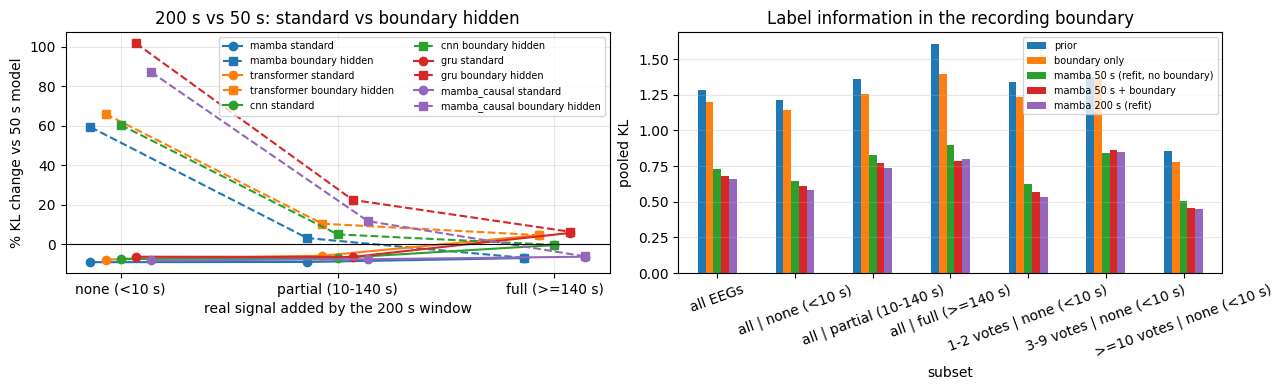

outputs in /kaggle/working/shortcut : ['boundary_information.csv', 'clean_50s_architecture.csv', 'cnn_ctx200_reflect_oofpred.npy', 'cnn_ctx200_standard_oofpred.npy', 'cnn_ctx200_truncate_oofpred.npy', 'gru_ctx200_reflect_oofpred.npy', 'gru_ctx200_standard_oofpred.npy', 'gru_ctx200_truncate_oofpred.npy', 'intervention_kl.csv', 'mamba_causal_ctx200_reflect_oofpred.npy', 'mamba_causal_ctx200_standard_oofpred.npy', 'mamba_causal_ctx200_truncate_oofpred.npy', 'mamba_ctx200_reflect_oofpred.npy', 'mamba_ctx200_standard_oofpred.npy', 'mamba_ctx200_truncate_oofpred.npy', 'prediction_shift.csv', 'shortcut_check.png', 'transformer_ctx200_reflect_oofpred.npy', 'transformer_ctx200_standard_oofpred.npy', 'transformer_ctx200_truncate_oofpred.npy']


In [17]:
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    ax = axes[0]
    g_ = inter_df[inter_df.subset.str.startswith("all |")]
    for i_, name in enumerate(g_.model.unique()):
        gg = g_[g_.model == name].set_index("subset").reindex([f"all | {b}" for b in CFG["CTX_LABELS"]])
        xs = np.arange(len(CFG["CTX_LABELS"])) + (i_ - 2) * 0.07
        if "gain_sta_pct" in gg:
            ax.plot(xs, gg["gain_sta_pct"], "o-", color=f"C{i_}", label=f"{name} standard")
            ax.plot(xs, gg["gain_ref_pct"], "s--", color=f"C{i_}", label=f"{name} boundary hidden")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(CFG["CTX_LABELS"]))); ax.set_xticklabels(CFG["CTX_LABELS"])
    ax.set_xlabel("real signal added by the 200 s window"); ax.set_ylabel("% KL change vs 50 s model"); ax.set_title("200 s vs 50 s: standard vs boundary hidden")
    ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
    ax = axes[1]
    sub = meta_df.set_index("subset")
    cols = [c for c in ["prior", "boundary only", "mamba 50 s (refit, no boundary)", "mamba 50 s + boundary", "mamba 200 s (refit)"] if c in sub]
    sub[cols].plot.bar(ax=ax); ax.set_ylabel("pooled KL"); ax.set_title("Label information in the recording boundary"); ax.grid(alpha=0.3, axis="y")
    ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/shortcut_check.png", dpi=150); plt.show()
except Exception as e:
    print("plot skipped:", e)
print("outputs in", CFG["OUT_DIR"], ":", sorted(os.listdir(CFG["OUT_DIR"])))